# 02. 상담 예제 1 — "카드가 안 긁히는데 어떻게 해야 하나요?" (clarification loop)

첫 번째 상담 예제입니다. 고객 문의에 **구체 정보가 없어서**, agent가 D5(정보 충분성)에서 `need_clarification`을 판정하고 **되묻는 질문을 생성 -> 고객 답변 수신 -> 재판정**하는 recursive loop를 돕니다.

예상 경로:
```
D1(guardrail) -> D2(routing) -> D5(need_clarification) -> 되묻기/답변 -> D5(info_sufficient)
-> D3(tool 선택) -> tool 성공 -> D6(goal_met) -> 요약 -> D7(no_risk) -> D4(resolve) -> 최종 응답
```

같은 질문을 **① Haiku 판단**으로, **② SGLang 판단**으로 각각 실행하며 STEP별 출력을 관찰하고, 마지막에 수행시간을 비교합니다. (응답 생성은 양쪽 모두 Sonnet 4.5 — 차이는 판단 계층뿐)

In [1]:
import sys; sys.path.insert(0, "/home/ubuntu/LLMRouter/OpenSource/workshop")  # ws_common 경로
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[1]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script(실습 재현용 사전 설정):", sc["script"])

시나리오: 모호한 문의 -> clarification loop
고객 질문: 카드가 안 긁히는데 어떻게 해야 하나요?
script(실습 재현용 사전 설정): {'vague': True, 'clarify_reply': '어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.', 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['success'], 'risk_flag': False, 'kyc_result': None}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): 접수 심사 -> 업무 분류 -> **되묻기 loop(clarify_gate <-> ask_clarify)** -> tool 1회 성공 -> 요약 -> 리스크 이상 없음 -> 종결. KYC sub-flow와 give_up 경로는 이번에는 지나가지 않습니다.

배정 상담팀(빨간 표시): **cards(카드 발급/배송)** — 카드 오작동 문의이므로 cards 팀 tool(card_troubleshoot)로 처리됩니다.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `01_build_agent.ipynb` 참조).


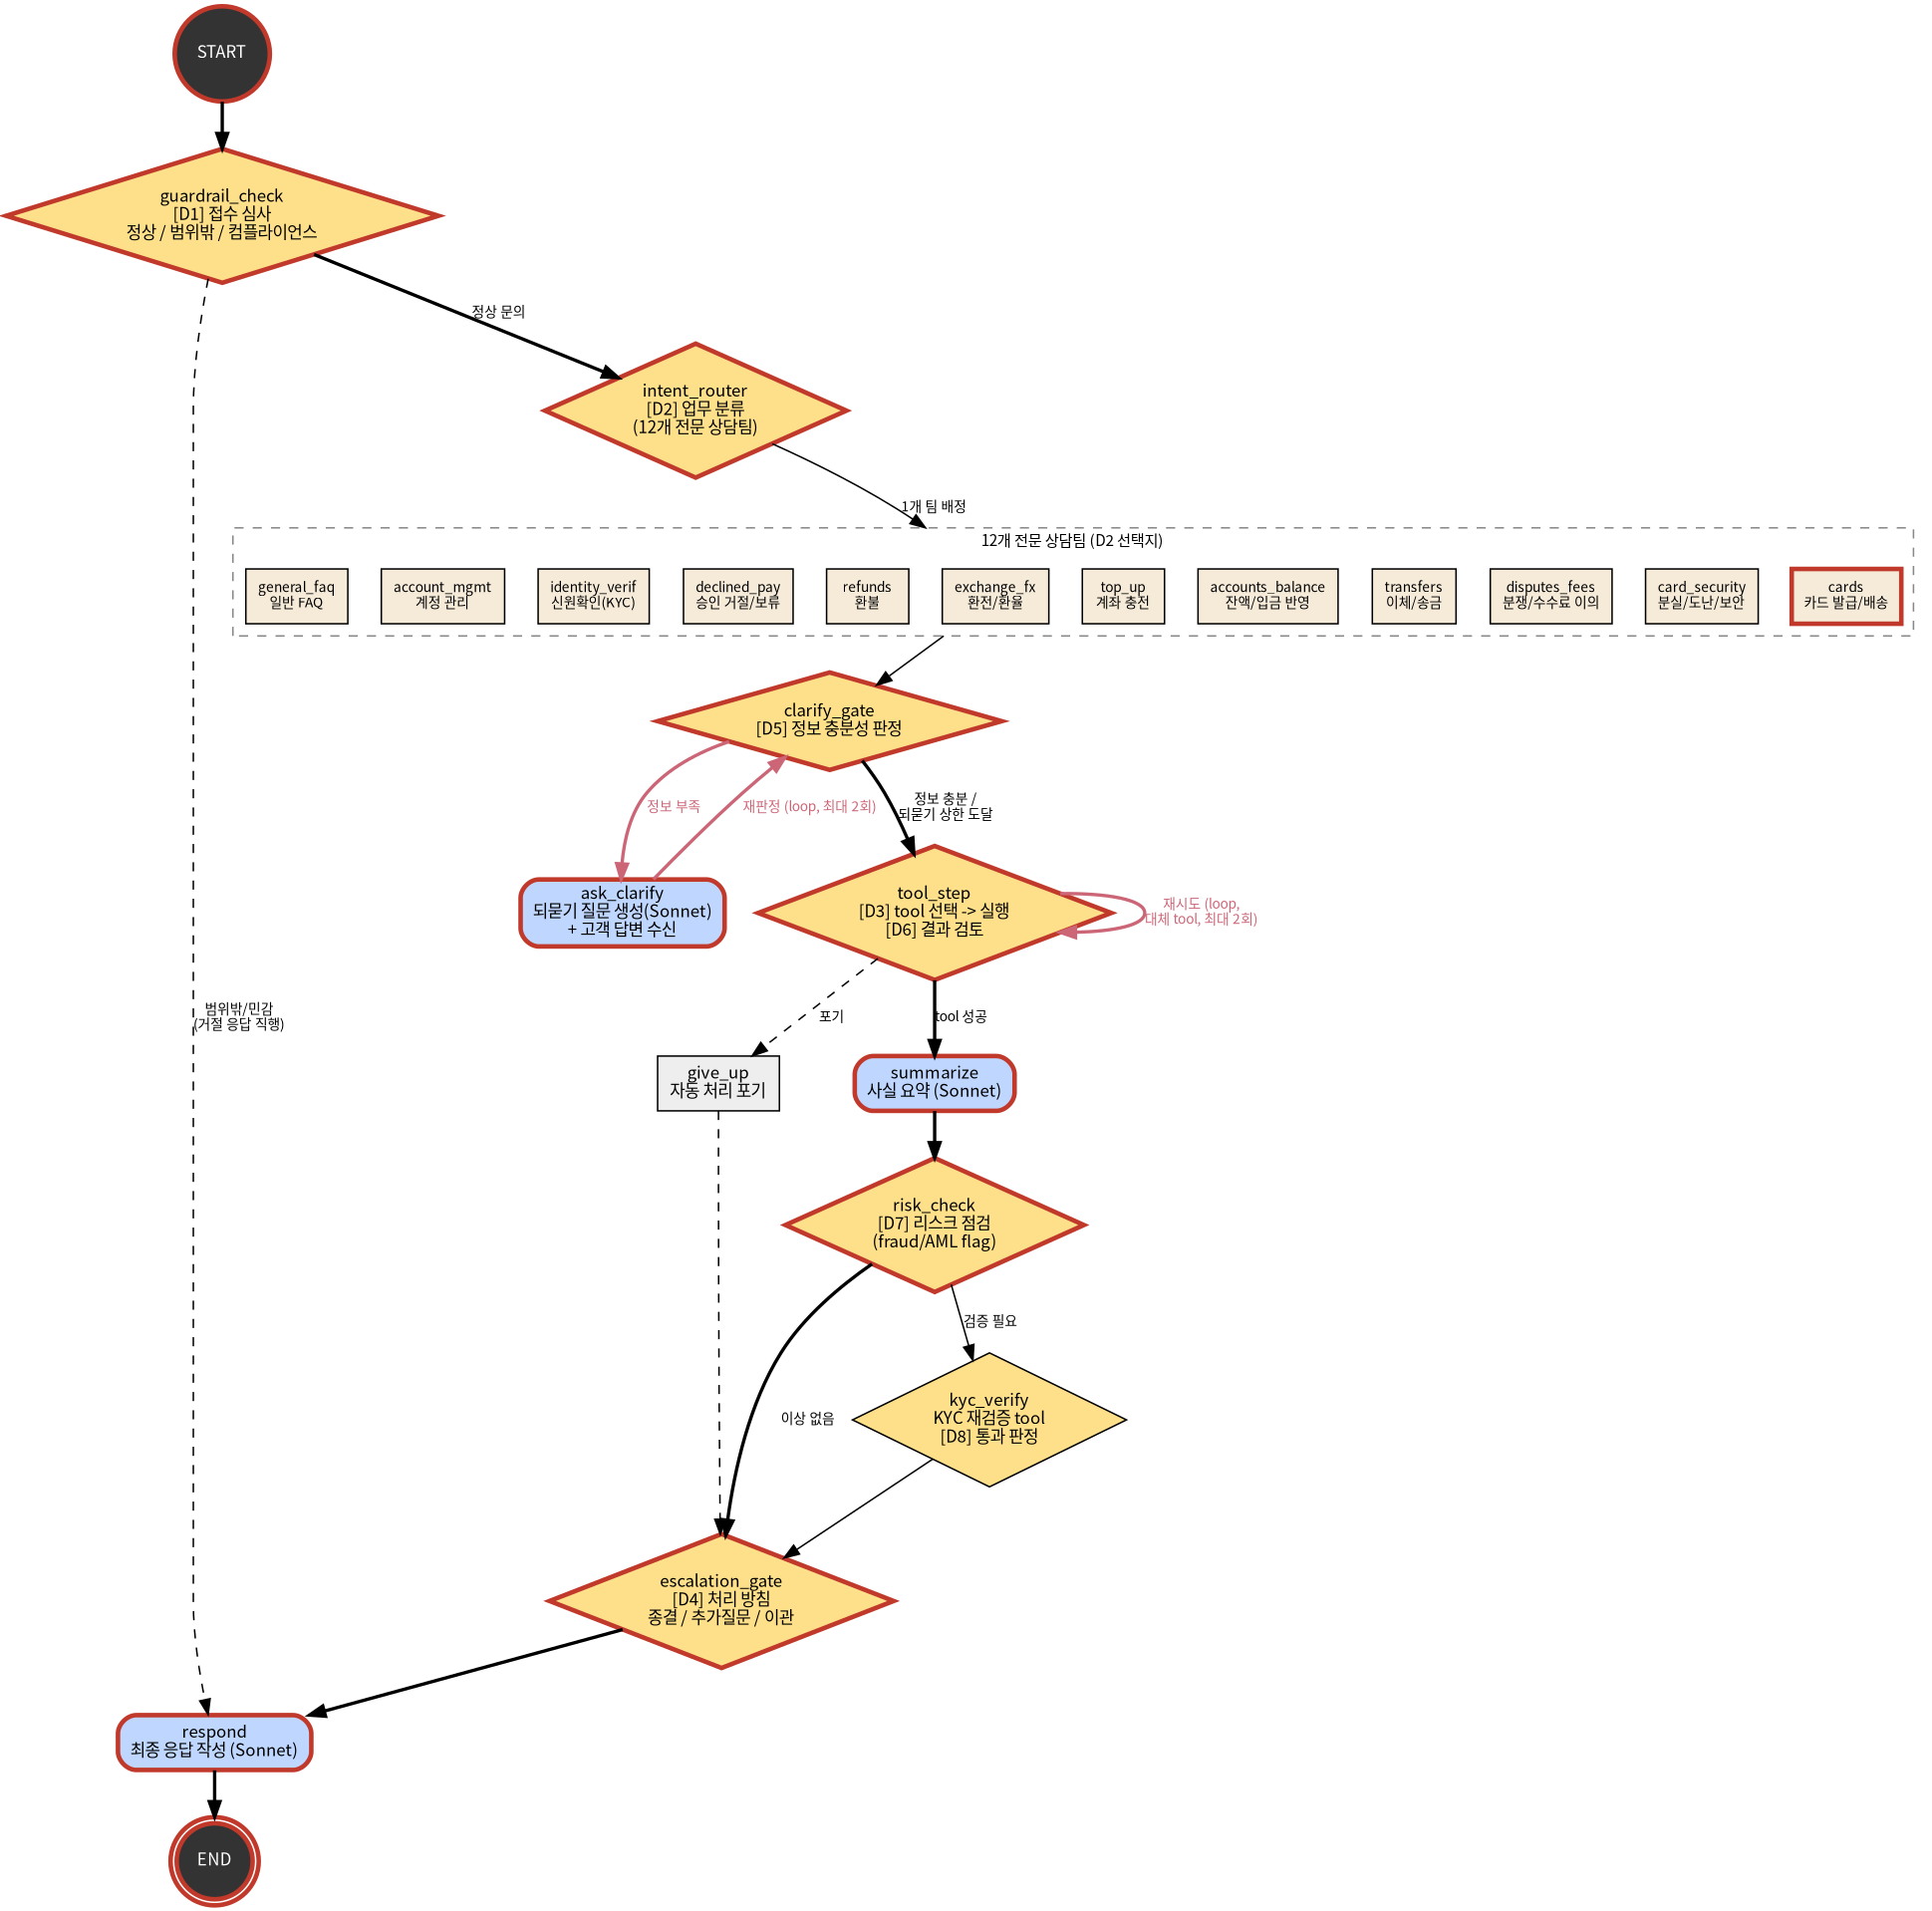

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[1], show_teams=True, width=760)

## ① Haiku 4.5가 판단하는 agent로 실행

각 STEP에서 어떤 노드가 어떤 판정(label)을 몇 ms에 내리는지, 되묻는 질문과 고객 답변, 최종 응답까지 그대로 출력됩니다. **판정 한 번마다 600ms 이상** 걸리는 것을 눈여겨보세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 카드가 안 긁히는데 어떻게 해야 하나요?



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (925ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (601ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> need_clarification   (1,159ms)



STEP 4 ▶ ask_clarify — 되묻기: Sonnet이 질문 생성 -> 고객 답변 수신
      생성(Sonnet 4.5)   (1,932ms)
      상담 agent: 어떤 카드가 안 되시나요? 실물 카드인가요, 아니면 모바일 카드인가요?
      고객: 어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.


...


STEP 6 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> card_troubleshoot   (682ms)
      tool 실행: card_troubleshoot   (0.0ms)
      판정[D6] -> goal_met   (675ms)



STEP 7 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (3,212ms)
      요약(첫 줄): Based on the tool execution result, here are the key resolution facts:



STEP 8 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (612ms)



STEP 9 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> resolve   (670ms)



STEP 10 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (4,887ms)
      --- 최종 응답 ---
      고객님, 카드 문제를 확인하여 시스템 조치를 완료했습니다. 
      
      Visa 체크카드(끝자리 7712)에 대한 트러블슈팅이 정상적으로 처리되었으며, 이제 오프라인 매장에서 정상적으로 사용하실 수 있습니다.
      
      약 10-20분 후 다시 결제를 시도해 주시기 바랍니다. 만약 여전히 문제가 발생하시면 참조번호 **REF-ws-Haiku-21207**을 알려주시면 신속하게 도와드리겠습니다.
      
      이용에 불편을 드려 죄송합니다. 추가 문의사항이 있으시면 언제든지 연락 주세요.

>>> [Haiku] 결정 8회 합계 6,322ms | 생성 10,031ms | e2e 16,363ms


## ② SGLang(Qwen3-VL-8B) 판단으로 실행

같은 그래프, 같은 질문입니다. 판정이 **30-50ms**에 끝나고 **confidence**가 함께 찍히는 점이 다릅니다.

In [4]:
res_sglang = W.run_verbose(graphs["SGLang"], sc["question"], sc["script"], "SGLang")


[SGLang] 고객: 카드가 안 긁히는데 어떻게 해야 하나요?

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (53ms, confidence 1.000)

STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> cards   (34ms, confidence 1.000)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> need_clarification   (33ms, confidence 1.000)



STEP 4 ▶ ask_clarify — 되묻기: Sonnet이 질문 생성 -> 고객 답변 수신
      생성(Sonnet 4.5)   (3,216ms)
      상담 agent: 어떤 카드가 안 되시나요? 체크카드인가요, 신용카드인가요?
      고객: 어제부터 오프라인 매장 단말기에서만 승인이 거절돼요. 관련 정보: Visa 체크카드(끝자리 7712), 마지막 시도 2026-10-27 TechMart 강남점, 금액 45,000원입니다.

STEP 5 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (37ms, confidence 1.000)

STEP 6 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> card_troubleshoot   (34ms, confidence 1.000)
      tool 실행: card_troubleshoot   (0.0ms)
      판정[D6] -> goal_met   (35ms, confidence 1.000)



STEP 7 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(Sonnet 4.5)   (4,119ms)
      요약(첫 줄): Based on the tool execution result, here are the key resolution facts:

STEP 8 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> no_risk   (38ms, confidence 1.000)

STEP 9 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> resolve   (36ms, confidence 1.000)



STEP 10 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(Sonnet 4.5)   (4,938ms)
      --- 최종 응답 ---
      고객님의 Visa 체크카드(끝자리 7712) 오프라인 결제 문제를 해결했습니다.
      
      시스템에서 기술적 문제를 처리했으며, 이제 TechMart 강남점을 포함한 오프라인 매장에서 정상적으로 카드 결제가 가능합니다.
      
      다시 한 번 결제를 시도해 주시기 바랍니다. 만약 여전히 승인이 거절되는 경우, 추가 확인이 필요할 수 있으니 다시 연락 주시면 카드 재발급 등 추가 조치를 도와드리겠습니다.
      
      **참조번호: REF-ws-SGLang-21224**
      
      불편을 드려 죄송하며, 추가 문의사항이 있으시면 언제든지 연락 주세요.

>>> [SGLang] 결정 8회 합계 299ms | 생성 12,272ms | e2e 12,579ms


## ③ 수행시간 비교

생성(Sonnet) 시간은 양쪽이 비슷하고, **판단 계층의 시간이 통째로 사라지는 것**이 핵심입니다.

In [5]:
W.compare(res_haiku, res_sglang)

| 지표 | Haiku | SGLang | 배수(Haiku/SGLang) |
|---|---:|---:|---:|
| 결정 횟수 | 8 | 8 | |
| **결정 latency 합계** | **6,322ms** | **299ms** | **21.1x** |
| 생성(LLM) latency | 10,031ms | 12,272ms | **0.8x** |
| e2e | 16,363ms | 12,579ms | **1.3x** |

**결정 계층 속도 차이: 21.1x** (e2e 단축 3,783ms)

**결정별 latency**

| 노드 | 결정 | Haiku | SGLang | 배수 | 판정 label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 925ms | 53ms | **17.4x** | in_scope (동일) |
| intent_router | D2 | 601ms | 34ms | **17.6x** | cards (동일) |
| clarify_gate | D5 | 1,159ms | 33ms | **35.0x** | need_clarification (동일) |
| clarify_gate | D5 | 997ms | 37ms | **27.3x** | info_sufficient (동일) |
| tool_select | D3 | 682ms | 34ms | **20.2x** | card_troubleshoot (동일) |
| tool_review | D6 | 675ms | 35ms | **19.4x** | goal_met (동일) |
| risk_check | D7 | 612ms | 38ms | **15.9x** | no_risk (동일) |
| escalation_gate | D4 | 670ms | 36ms | **18.8x** | resolve (동일) |

**관찰 포인트**
- 되묻기 loop 때문에 D5가 두 번 실행됩니다 — loop가 돌수록 판단 횟수가 늘고, 판단이 느린 backend일수록 누적 격차가 커집니다.
- 두 arm의 판정 label이 같은지 비교해 보세요(비교표 우측). label이 같다면 이 대화에서는 품질 손실 없이 속도만 얻은 것입니다.
- 다음: `03_scenario2_retry.ipynb` — tool이 실패했을 때 agent가 스스로 복구하는 loop.